# Phenotype-associated cells from bulk cohorts with Scissor

Clinical phenotypes such as survival or mutation status are measured on large bulk cohorts (for example TCGA), while single-cell data come from a handful of patients. **Scissor** (Sun *et al.*, *Nat Biotechnol* 2022) links the two: it correlates every cell with every bulk sample and fits a network-regularised regression of the bulk phenotype on these correlations. Cells with a non-zero coefficient are selected — **Scissor+** cells point towards the phenotype coded as positive (mutant, higher hazard) and **Scissor−** cells towards the other one; all remaining cells are *background*.

`ov.single.Scissor` wraps the independent, R-free [`scissor_py`](https://github.com/omicverse/py-Scissors) backend (see the backend documentation for the precise scope of its separate numerical validation). Three regression families are supported:

| `family=` | Phenotype | Scissor+ means |
|---|---|---|
| `'cox'` | `time` / `status` (1 event, 0 censored) | higher hazard (worse survival) |
| `'binomial'` | two classes + `positive_label` | the positive class |
| `'gaussian'` | continuous value | higher value |

This tutorial demonstrates the two lung adenocarcinoma (LUAD) applications of the [official Scissor tutorial](https://sunduanchen.github.io/Scissor/vignettes/Scissor_Tutorial.html) and of the paper with real data: 4,102 LUAD cancer cells guided by (1) overall survival of 471 TCGA-LUAD patients (Cox) and (2) *TP53* mutation status of 498 TCGA-LUAD tumours (binomial). The official example data contain no continuous phenotype, so `family='gaussian'` is only described, not run.

The backend is an optional dependency; install it once into the notebook's environment:

```sh
pip install "git+https://github.com/omicverse/py-Scissors.git@cc630ae828149202b553fb7dfdaeda2d0b94d1d7"
```

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import omicverse as ov

ov.plot_set()

<site-packages>\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)


🔬 Starting plot initialization...
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA GeForce RTX 5060 Ti
      Memory: 15.9 GB | Compute: 12.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Data

The five input files of the official tutorial (`scRNA-seq.RData`, `TCGA_LUAD_exp1/exp2.RData`, `TCGA_LUAD_survival.RData`, `TCGA_LUAD_TP53_mutation.RData`, hosted by the Scissor authors) were converted to `.h5ad` without removing any cell, sample or gene (conversion script and SHA-256 of the source files are in the [`scissor-v1` release](https://github.com/omicverse/omicverse-data/releases/tag/scissor-v1)).

* `scissor_luad_sc.h5ad` — raw UMI counts of 4,102 LUAD **cancer cells** × 33,694 genes (Lambrechts *et al.*, *Nat Med* 2018); the suffix of each barcode is the sample.
* `scissor_luad_bulk_survival.h5ad` — 471 TCGA-LUAD tumours × 56,716 genes with `obs['time']` (days) and `obs['status']`.
* `scissor_luad_bulk_tp53.h5ad` — 498 TCGA-LUAD tumours × 56,716 genes with `obs['TP53']` (`'mutant'` / `'wild-type'`).

In [2]:
url = 'https://github.com/omicverse/omicverse-data/releases/download/scissor-v1/'
files = ['scissor_luad_sc.h5ad', 'scissor_luad_bulk_survival.h5ad', 'scissor_luad_bulk_tp53.h5ad']
paths = [ov.datasets.download_data(url + f, dir='data/scissor') for f in files]
adata, bulk_os, bulk_tp53 = [ov.read(p) for p in paths]
adata

🔍 Downloading data to data/scissor\scissor_luad_sc.h5ad
⚠️ File data/scissor\scissor_luad_sc.h5ad already exists
🔍 Downloading data to data/scissor\scissor_luad_bulk_survival.h5ad
⚠️ File data/scissor\scissor_luad_bulk_survival.h5ad already exists
🔍 Downloading data to data/scissor\scissor_luad_bulk_tp53.h5ad
⚠️ File data/scissor\scissor_luad_bulk_tp53.h5ad already exists


AnnData object with n_obs × n_vars = 4102 × 33694
    obs: 'patient_batch'
    uns: 'source'

In [3]:
print(bulk_os.shape, bulk_os.obs['status'].value_counts().to_dict())
print(bulk_tp53.shape, bulk_tp53.obs['TP53'].value_counts().to_dict())

(471, 56716) {0: 350, 1: 121}
(498, 56716) {'mutant': 255, 'wild-type': 243}


## 2. Single-cell preprocessing and cell graph

The original `Seurat_preprocessing()` first filters genes with `min.cells=400`, **before** library-size normalization. Preserve all 4,102 cells, retain genes detected in at least 400 cells, then compute log1p counts per 10,000 using the retained genes. This order changes both library-size denominators and the shared genes used for bulk–cell correlations. Omitting this filter does not reproduce the original inputs.

The expression layer contains all **retained** genes, not just HVGs. This native OmicVerse example uses Pearson-residual HVGs and a 20-neighbour connectivity graph on 10 PCs. The original uses Seurat VST HVGs and an SNN graph; these are distinct network inputs. Matching gene filtering alone does not make the two workflows identical.


In [4]:
adata.obs['n_genes_raw'] = np.asarray((adata.X > 0).sum(axis=1)).ravel()
keep = np.asarray((adata.X > 0).sum(axis=0)).ravel() >= 400
adata = adata[:, keep].copy()
print(f'After min.cells=400: {adata.n_obs} cells, {adata.n_vars} genes')
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', target_sum=1e4,
                         n_HVGs=2000, identify_robust=False,
                         exclude_highly_expressed=False)
adata.layers['lognorm'] = adata.X.copy()
adata.raw = adata

After min.cells=400: 4102 cells, 5857 genes


🔍 [2026-11-10 23:53:20] Running preprocessing in 'cpu' mode...
Begin robust gene identification
Begin size normalization: shiftlog and HVGs selection pearson

🔍 Count Normalization:
   Target sum: 10000.0
   Exclude highly expressed: False

✅ Count Normalization Completed Successfully!
   ✓ Processed: 4,102 cells × 5,857 genes
   ✓ Runtime: 0.04s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 5,857 total (34.1%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 1.07 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ────────────────────

In [5]:
ov.pp.scale(adata)
ov.pp.pca(adata, n_pcs=10, layer='scaled')
ov.pp.neighbors(adata, n_neighbors=20, n_pcs=10, use_rep='scaled|original|X_pca')
ov.pp.umap(adata)
ov.pp.leiden(adata, resolution=0.6)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.1952s                                                 │
│  Shape:    4,102 x 5,857 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 4102x5857)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=10
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (4102, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (2.67s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 2.6716s                                                 │
│  Shape:    4,102 x 5,857 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 4102x10)                               │
│           │ ✚ scaled|original|X_pca (array, 4102x10)               │
│         

   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity


   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 4,102 cells with 20 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 9.2829s                                                 │
│  Shape:    4,102 x 5,857 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 20, 'method': 'umap', 'random_s...│
│                                                                    │
│  ● OBSP   │ ✚ connectivit


✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 4,102 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 0.7084s                                                 │
│  Shape:    4,102 x 5,857 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': 0.5830300198678042, 'b': 1.3341669929396847}│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 4102x2)                               │
│                 

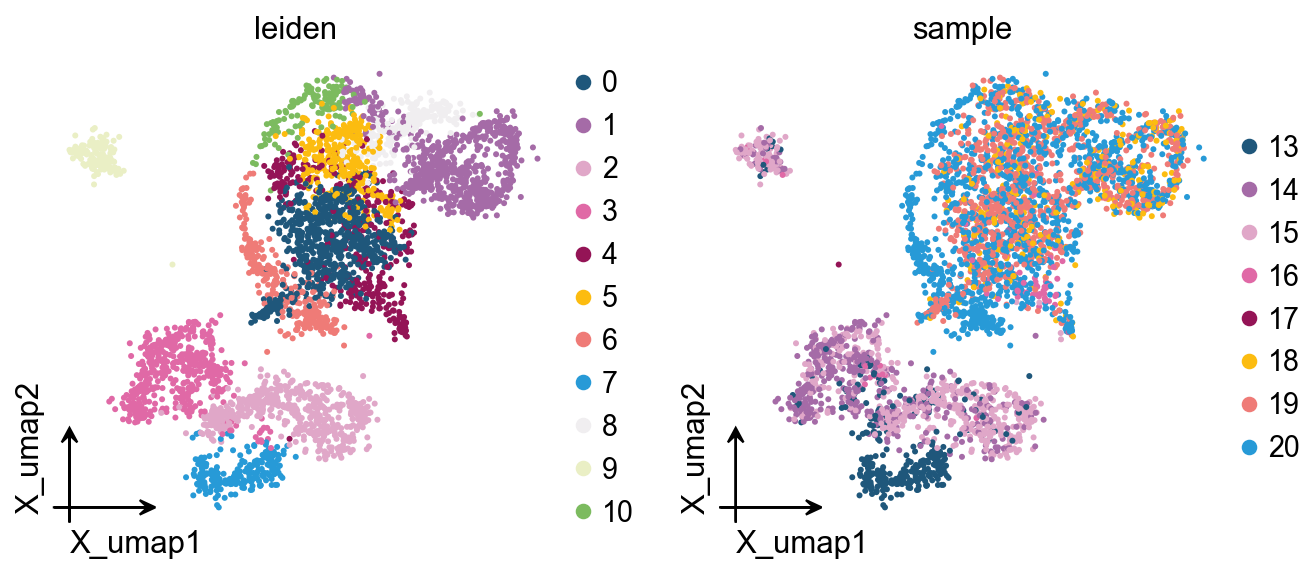

In [6]:
adata.obs['sample'] = adata.obs['patient_batch']
ov.pl.embedding(adata, basis='X_umap', color=['leiden', 'sample'], wspace=0.35, frameon='small')

The UMAP shows clusters and sample composition. Clustering is descriptive; Scissor fits coefficients for individual cells.


## 3. Bulk expression and phenotype

`Scissor` expects bulk expression as a **genes × samples** DataFrame with unique gene IDs, and refuses duplicated IDs instead of guessing how to merge them. The TCGA matrices contain 1,485 duplicated gene symbols; the original R implementation implicitly uses the first row of each symbol, so we make the same choice explicitly. Shared genes between bulk and single-cell data are then intersected inside Scissor (the size is determined after the gene filter above).

For Cox regression the phenotype is a DataFrame with exactly the columns `time` and `status`, indexed by the bulk sample IDs.

In [7]:
def bulk_frame(bdata):
    expr = bdata.to_df().T
    return expr[~expr.index.duplicated(keep='first')]

expr_os = bulk_frame(bulk_os)
pheno_os = bulk_os.obs[['time', 'status']]
expr_os.shape, int(pheno_os['status'].sum())

((55231, 471), 121)

## 4. Cells associated with worse survival (Cox)

Key parameters:

* `alpha` — balance between the L1 (sparsity) and the network penalty. Larger `alpha` puts more weight on sparsity; the selected count also depends on cross-validation. A list is searched in order and the first `alpha` whose selected fraction is below `cutoff` is kept (default `cutoff=0.2`, i.e. at most 20 % of cells). We use the official value `alpha=0.05`.
* `semantics` — `'official'` follows the pinned R implementation on its supported, well-defined inputs, but the R code indexes the graph unsafely for the Cox and Gaussian families on a connected graph, so `scissor_py` refuses that combination. `'corrected'` fixes the indexing (and a few numerical details, see the [semantics notes](https://github.com/omicverse/py-Scissors/blob/cc630ae828149202b553fb7dfdaeda2d0b94d1d7/docs/SEMANTICS.md)) and is required here.
* `lambda` is chosen by 10-fold cross-validation (`nfolds`, `nlambda=100` as in R). `max_dense_bytes` raises the guard for the dense expression matrices and temporary preprocessing arrays.

In [8]:
cox = ov.single.Scissor(adata, bulk=expr_os, phenotype=pheno_os, family='cox',
                        layer='lognorm', graph_key='connectivities',
                        semantics='corrected', key_added='scissor_os')
res_os = cox.run(alpha=0.05, nfolds=10, random_state=123, max_dense_bytes=4_000_000_000)
print(f"alpha = {res_os.alpha}, lambda = {res_os.lambda_min:.4f}")
adata.obs['scissor_os'].value_counts()

alpha = 0.05, lambda = 0.0323


scissor_os
background    3873
Scissor+       209
Scissor-        20
Name: count, dtype: int64

The output above reports the current selection. The historical R vignette reports 201 positive and 4 negative cells, but it uses a different graph, R-generated CV folds and original Cox semantics. These historical counts are a reference, not an equality test.


In [9]:
vignette_pos = ['AAAGTAGAGGAGCGAG_19', 'AACCATGCATCTCCCA_19', 'AACCGCGAGCTGCGAA_20', 'AACTCAGTCCGCGGTA_19']
vignette_neg = ['ACGCCAGTCCTCCTAG_20', 'ACGGGCTAGTGGCACA_20', 'CCGGTAGGTACCCAAT_15', 'GACGCGTAGTGGTCCC_20']
print('vignette Scissor+ cells:', adata.obs.loc[vignette_pos, 'scissor_os'].tolist())
print('vignette Scissor- cells:', adata.obs.loc[vignette_neg, 'scissor_os'].tolist())

vignette Scissor+ cells: ['Scissor+', 'Scissor+', 'background', 'background']
vignette Scissor- cells: ['Scissor-', 'Scissor-', 'Scissor-', 'Scissor-']


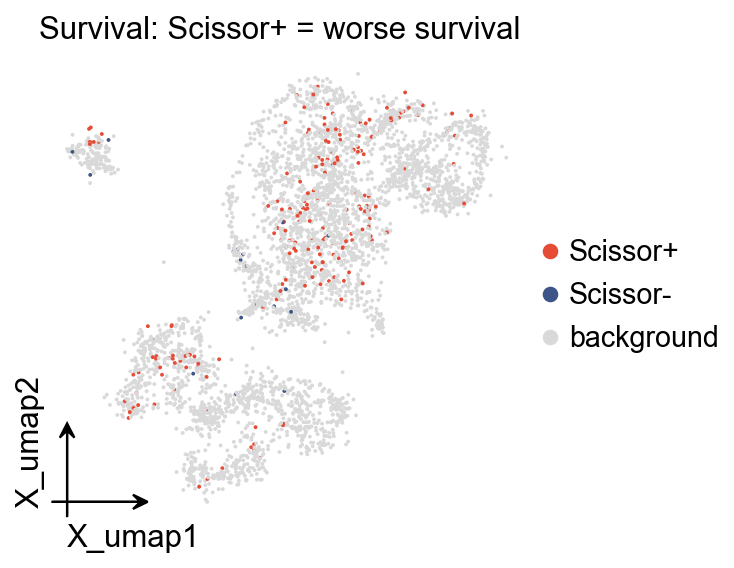

In [10]:
palette = {'Scissor+': '#e64b35', 'Scissor-': '#3c5488', 'background': '#d9d9d9'}
ov.pl.embedding(adata, basis='X_umap', color='scissor_os', palette=palette,
                size=12, frameon='small', title='Survival: Scissor+ = worse survival')

In [11]:
pd.crosstab(adata.obs['leiden'], adata.obs['scissor_os']).query('`Scissor+` > 0')

scissor_os  Scissor+  Scissor-  background
leiden                                    
0                 68         4         653
1                 10         0         662
2                  4         2         514
3                 36         2         458
4                  5         1         347
5                 41         0         307
7                  7         0         221
8                 22         0         189
9                  8         3         131
10                 8         0         126

The barcode checks above compare only the few example cells printed in the R vignette. They do not establish the overlap of the complete selections. The cross-tabulation describes how selected cells are distributed across clusters.


### What characterises the worse-survival cells?

The paper reports that Scissor+ cells for survival over-express **hypoxia** genes (HIF1A targets, glycolysis). We test this with a Wilcoxon test of Scissor+ cells against all other cells and with AUCell scores of Hallmark gene sets (MSigDB v7.5.1, shipped with OmicVerse).

In [12]:
ov.single.find_markers(adata, groupby='scissor_os', method='wilcoxon', groups=['Scissor+'],
                       reference='rest', n_genes=adata.n_vars, key_added='de_os')
de_os = ov.single.get_markers(adata, n_genes=adata.n_vars, key='de_os', groups='Scissor+').set_index('names')
de_os.head(25)

🔍 Finding marker genes | method: wilcoxon | groupby: scissor_os | n_groups: 1 | n_genes: 5857


✅ Done | 1 groups × 5857 genes | corr: benjamini-hochberg | stored in adata.uns['de_os']


             group  rank     scores  logfoldchanges         pvals  \
names                                                               
GAPDH     Scissor+     1  16.536604        1.249703  1.999818e-61   
ENO1      Scissor+     2  11.887733        1.471676  1.370765e-32   
ACTB      Scissor+     3  11.482139        0.986009  1.622180e-30   
TPI1      Scissor+     4  10.347043        0.938366  4.316120e-25   
TMSB10    Scissor+     5  10.345634        0.630824  4.380084e-25   
ACTG1     Scissor+     6   9.645600        1.048697  5.130993e-22   
PKM       Scissor+     7   9.221479        1.184390  2.930278e-20   
ALDOA     Scissor+     8   8.203266        0.948910  2.339425e-16   
LDHA      Scissor+     9   8.118580        0.987564  4.716702e-16   
PGK1      Scissor+    10   7.585701        1.356086  3.306944e-14   
TUBB      Scissor+    11   7.216349        0.989425  5.340193e-13   
PTMA      Scissor+    12   5.726410        0.391183  1.025780e-08   
NDUFA4L2  Scissor+    13   5.51090

Inspect the ranked genes above for evidence of the hypoxia/glycolysis programmes discussed in the original paper. The displayed table, rather than results from an earlier run, is the basis for interpretation.


In [13]:
from pathlib import Path

hallmark_path = Path(ov.datasets.predefined_signatures['hallmark'])
if not hallmark_path.is_file():
    # Some wheels omit the GMT data file. Use the same version from pinned source.
    hallmark_url = ('https://raw.githubusercontent.com/omicverse/omicverse/'
                    'db7be141626bcf547c229470ad1865c2067c68ba/'
                    'omicverse/datasets/data_files/h.all.v7.5.1.symbols.gmt')
    hallmark_path = Path(ov.datasets.download_data(hallmark_url, dir='data/scissor'))
hallmark = ov.datasets.load_signatures_from_file(str(hallmark_path))
sets = ['HALLMARK_HYPOXIA', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_E2F_TARGETS', 'HALLMARK_G2M_CHECKPOINT']
for s in sets:
    ov.single.geneset_aucell(adata, s, hallmark[s])
sets = [s + '_aucell' for s in sets]

🔍 Downloading data to data/scissor\h.all.v7.5.1.symbols.gmt
⚠️ File data/scissor\h.all.v7.5.1.symbols.gmt already exists
Loaded signatures from GMT file data\scissor\h.all.v7.5.1.symbols.gmt.
[ov.single AUCell] The new GPU-accelerated API is `ov.es.aucell` — pass signatures as a dict, e.g. `ov.es.aucell(adata, signatures={'name': genes}, engine='gpu')`. The legacy function still works.


  0%|          | 0/4102 [00:00<?, ?it/s]

 22%|██▏       | 905/4102 [00:00<00:00, 8973.61it/s]

 44%|████▍     | 1803/4102 [00:00<00:00, 7874.60it/s]

 64%|██████▎   | 2614/4102 [00:00<00:00, 7944.87it/s]

 85%|████████▌ | 3507/4102 [00:00<00:00, 8311.06it/s]

... (18 outputs left out)

 41%|████      | 1666/4102 [00:00<00:00, 7829.42it/s]

 60%|█████▉    | 2451/4102 [00:00<00:00, 7483.86it/s]

 81%|████████▏ | 3341/4102 [00:00<00:00, 7998.40it/s]

100%|██████████| 4102/4102 [00:00<00:00, 7775.91it/s]

In [14]:
from scipy.stats import mannwhitneyu

def compare_scores(obs, key, case, ref):
    a, b = obs[obs[key] == case], obs[obs[key].isin(ref)]
    return pd.DataFrame({'mean ' + case: a[sets].mean(), 'mean reference': b[sets].mean(),
                         'Mann-Whitney p': [mannwhitneyu(a[s], b[s]).pvalue for s in sets]})

compare_scores(adata.obs, 'scissor_os', 'Scissor+', ['background', 'Scissor-'])

                                mean Scissor+  mean reference  Mann-Whitney p
HALLMARK_HYPOXIA_aucell              0.028473        0.023955    6.660974e-12
HALLMARK_GLYCOLYSIS_aucell           0.027085        0.021035    2.308697e-19
HALLMARK_E2F_TARGETS_aucell          0.019207        0.014703    9.936081e-10
HALLMARK_G2M_CHECKPOINT_aucell       0.012772        0.010562    3.568787e-07

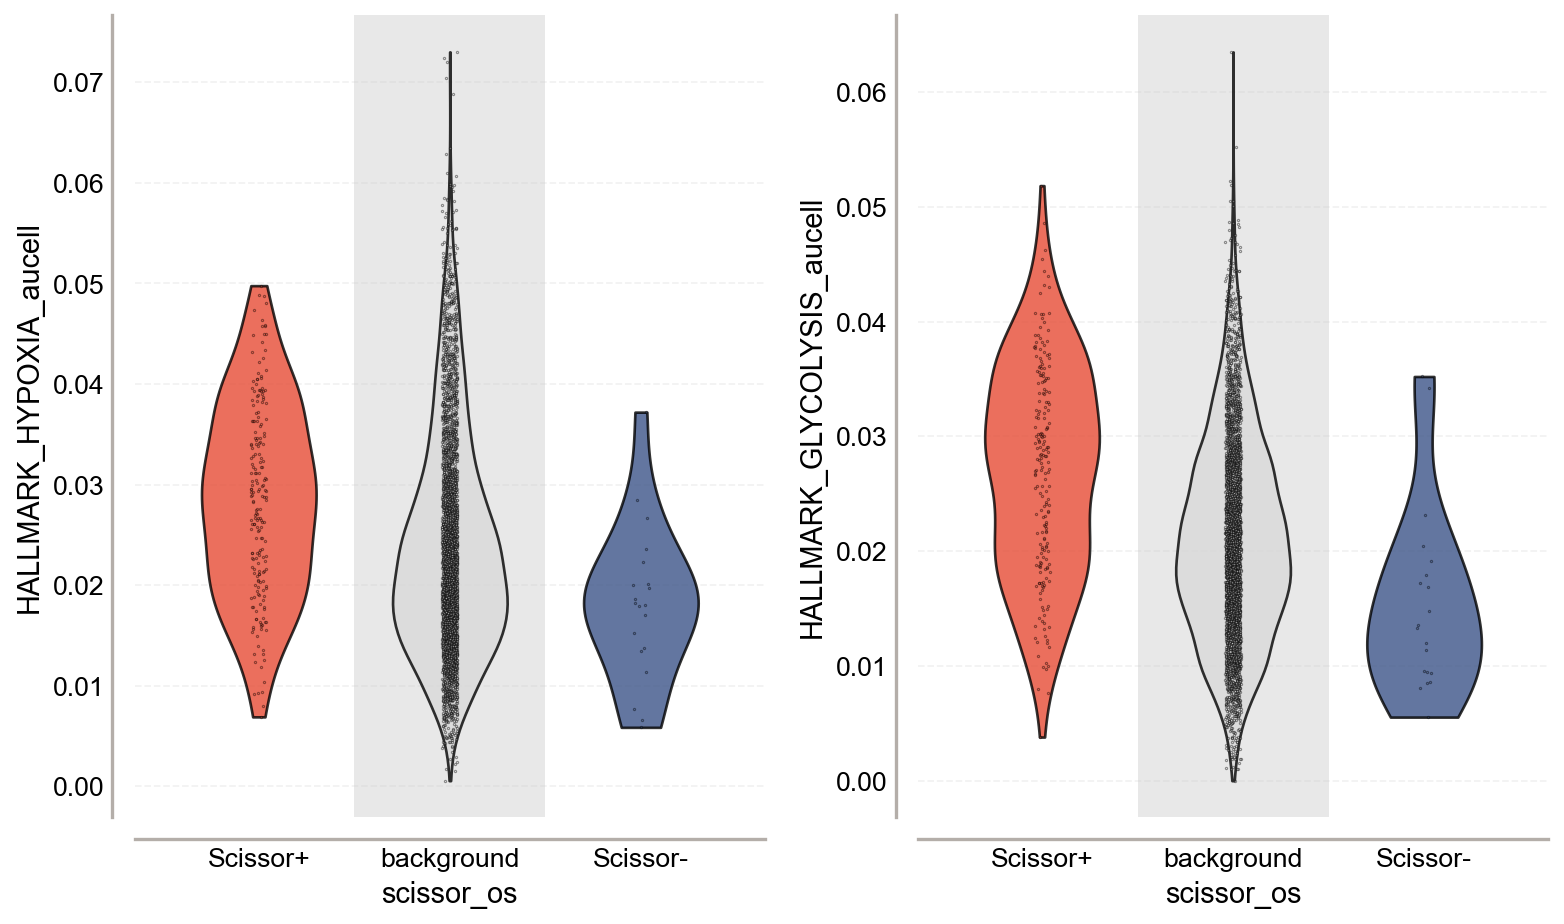

In [15]:
order = ['Scissor+', 'background', 'Scissor-']
ov.pl.violin(adata, keys=['HALLMARK_HYPOXIA_aucell', 'HALLMARK_GLYCOLYSIS_aucell'], groupby='scissor_os',
             order=order, custom_colors=[palette[g] for g in order])

Compare effect sizes and score distributions as well as cell-level p-values. These exploratory tests use cells from multiple patients and do not constitute independent patient-level validation.


### Sensitivity to detected-gene counts

Compare selected cells with background cells matched by deciles of the number of detected genes in the **original raw counts**, before the gene filter. This checks one potential confounder; it cannot rule out all technical or patient effects.


In [16]:
obs = adata.obs.assign(n_genes=adata.obs['n_genes_raw'])
obs['depth_bin'] = pd.qcut(obs['n_genes'], 10, labels=False)
pos = obs[obs['scissor_os'] == 'Scissor+']
bg = obs[obs['scissor_os'] == 'background']
matched = pd.concat([bg[bg['depth_bin'] == b].sample(min(5 * n, (bg['depth_bin'] == b).sum()), random_state=0)
                     for b, n in pos['depth_bin'].value_counts().items()])

In [17]:
print('median detected genes  Scissor+:', pos['n_genes'].median(), ' all background:', bg['n_genes'].median(),
      ' matched background:', matched['n_genes'].median())
compare_scores(pd.concat([pos, matched]), 'scissor_os', 'Scissor+', ['background'])

median detected genes  Scissor+: 701.0  all background: 957.0  matched background: 711.0


                                mean Scissor+  mean reference  Mann-Whitney p
HALLMARK_HYPOXIA_aucell              0.028473        0.021645    3.153991e-21
HALLMARK_GLYCOLYSIS_aucell           0.027085        0.019611    3.017086e-25
HALLMARK_E2F_TARGETS_aucell          0.019207        0.015236    8.151266e-07
HALLMARK_G2M_CHECKPOINT_aucell       0.012772        0.010819    6.062973e-05

Use the displayed matched comparison to assess whether the score differences persist after this adjustment. Persistence alone does not prove the absence of sequencing-depth effects or other confounding.


## 5. Cells associated with *TP53* mutation (binomial)

For a binary phenotype the sign of a coefficient depends on how the two classes are coded, so `positive_label` must be given for string labels: here Scissor+ cells point towards `'mutant'` and Scissor− cells towards `'wild-type'`. The binomial model does not have the Cox graph-indexing issue on the supported graph used here, so we keep `semantics='official'`. As in the paper we use `alpha=0.2`.

In [18]:
expr_tp53 = bulk_frame(bulk_tp53)
pheno_tp53 = bulk_tp53.obs['TP53']
tp53 = ov.single.Scissor(adata, bulk=expr_tp53, phenotype=pheno_tp53, family='binomial',
                         positive_label='mutant', layer='lognorm', graph_key='connectivities',
                         semantics='official', key_added='scissor_tp53')

In [19]:
res_tp53 = tp53.run(alpha=0.2, nfolds=10, random_state=123, max_dense_bytes=4_000_000_000)
print(f"alpha = {res_tp53.alpha}, lambda = {res_tp53.lambda_min:.4f}")
adata.obs['scissor_tp53'].value_counts()

alpha = 0.2, lambda = 0.0014


scissor_tp53
background    3363
Scissor+       415
Scissor-       324
Name: count, dtype: int64

The output above gives the current TP53 selection. The R vignette reports 414 positive and 318 negative cells at alpha=0.2. Different expression inputs, graph construction and CV folds can change the result even with the same alpha. Check `res_tp53.cutoff_reached`: a single alpha does not force the selected fraction below 20%; pass a list of alphas to search for a sparser model.


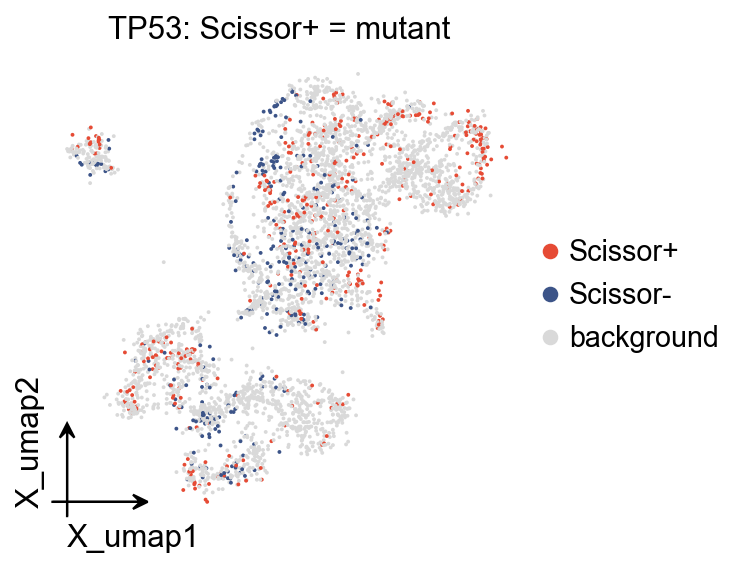

In [20]:
ov.pl.embedding(adata, basis='X_umap', color='scissor_tp53', palette=palette,
                size=12, frameon='small', title='TP53: Scissor+ = mutant')

The paper compares Scissor+ with Scissor− cells and finds E2F targets and cell-cycle genes (*AURKA*, *CDK1*, *CCNB2*, *TOP2A*) up in the mutant-associated cells, consistent with loss of p53-mediated cell-cycle arrest.

In [21]:
ov.single.find_markers(adata, groupby='scissor_tp53', method='wilcoxon', groups=['Scissor+'],
                       reference='Scissor-', n_genes=adata.n_vars, key_added='de_tp53')
de_tp53 = ov.single.get_markers(adata, n_genes=adata.n_vars, key='de_tp53', groups='Scissor+').set_index('names')
marker_genes = ['AURKA', 'CDK1', 'CCNB2', 'TOP2A', 'MKI67']
missing = [g for g in marker_genes if g not in de_tp53.index]
print('Markers excluded by the gene filter (not tested):', missing)
de_tp53.reindex(marker_genes)

🔍 Finding marker genes | method: wilcoxon | groupby: scissor_tp53 | n_groups: 1 | n_genes: 5857


✅ Done | 2 groups × 5857 genes | corr: benjamini-hochberg | stored in adata.uns['de_tp53']
Markers excluded by the gene filter (not tested): ['MKI67']


          group   rank    scores  logfoldchanges         pvals  pvals_adj  \
names                                                                       
AURKA  Scissor+  364.0  3.388399        2.213649  7.030198e-04   0.009643   
CDK1   Scissor+  785.0  2.718845        1.459647  6.551023e-03   0.044564   
CCNB2  Scissor+  342.0  3.439796        2.693758  5.821528e-04   0.008431   
TOP2A  Scissor+   43.0  4.956362        2.283224  7.182522e-07   0.000053   
MKI67       NaN    NaN       NaN             NaN           NaN        NaN   

       pct_group  
names             
AURKA   0.180723  
CDK1    0.212048  
CCNB2   0.180723  
TOP2A   0.303614  
MKI67        NaN  

In [22]:
compare_scores(adata.obs, 'scissor_tp53', 'Scissor+', ['Scissor-'])

                                mean Scissor+  mean reference  Mann-Whitney p
HALLMARK_HYPOXIA_aucell              0.021802        0.020139    2.620852e-02
HALLMARK_GLYCOLYSIS_aucell           0.020721        0.017273    4.168747e-09
HALLMARK_E2F_TARGETS_aucell          0.021034        0.010890    1.562168e-29
HALLMARK_G2M_CHECKPOINT_aucell       0.015388        0.008243    8.116133e-29

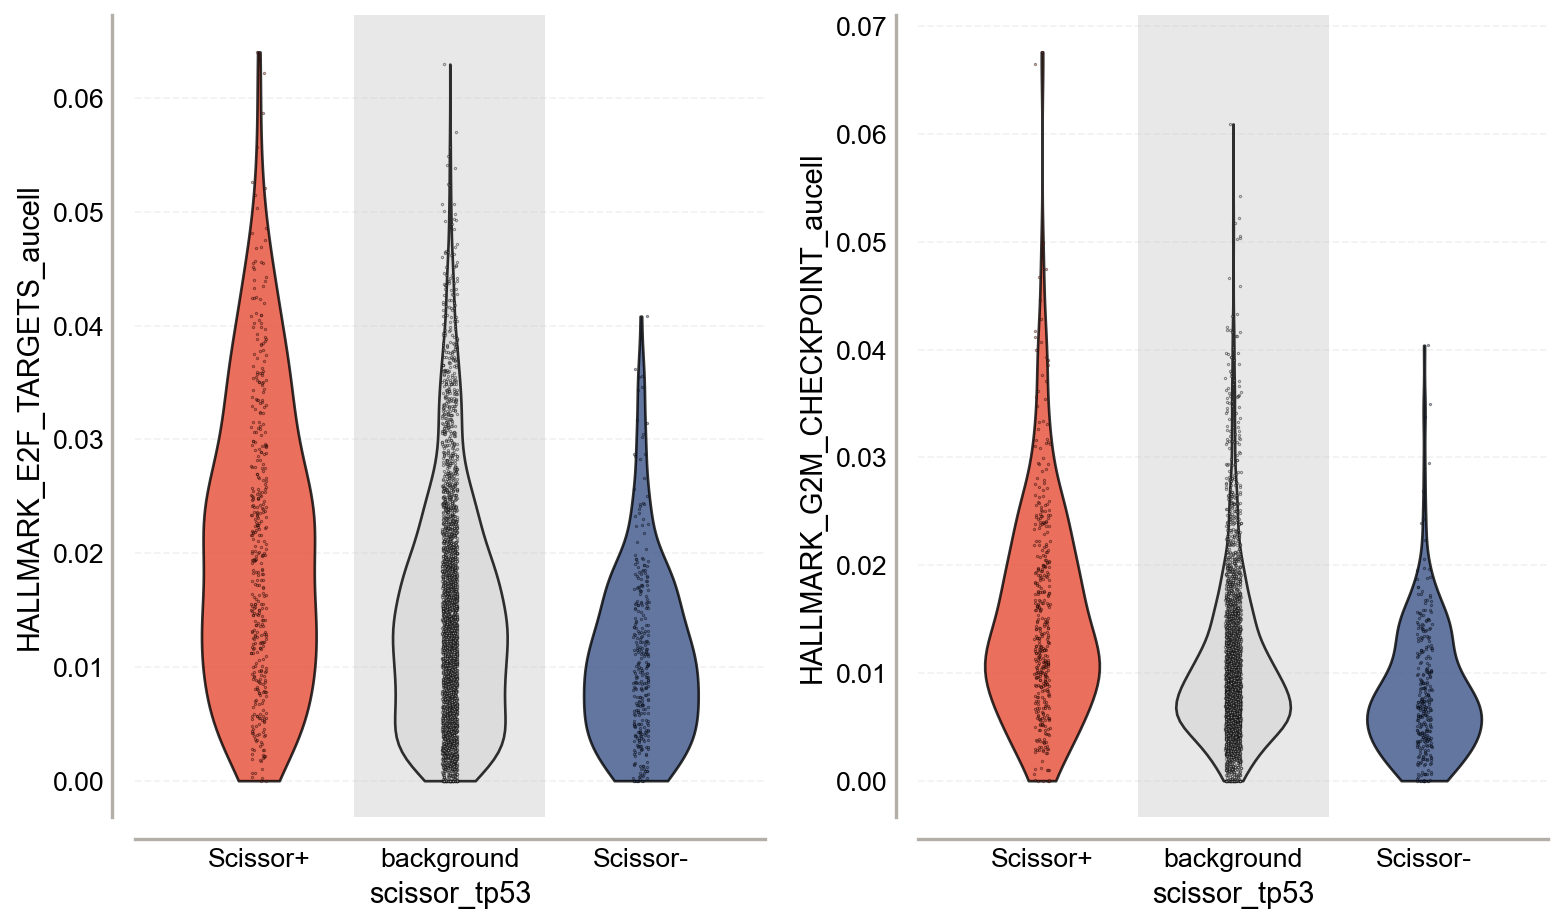

In [23]:
ov.pl.violin(adata, keys=['HALLMARK_E2F_TARGETS_aucell', 'HALLMARK_G2M_CHECKPOINT_aucell'], groupby='scissor_tp53',
             order=order, custom_colors=[palette[g] for g in order])

The marker table and pathway score comparisons test the proliferative programme highlighted in the original paper. Interpret their direction and magnitude from this run; these cell-level associations do not establish causality or patient-level predictive performance.


## 6. Comparing both analyses

Compare the two phenotype-specific selections directly.


In [24]:
pd.crosstab(adata.obs['scissor_os'], adata.obs['scissor_tp53'])

scissor_tp53  Scissor+  Scissor-  background
scissor_os                                  
Scissor+            38         7         164
Scissor-             0        11           9
background         377       306        3190

The cross-tabulation reports the complete overlap between the two models in this run. It is distinct from overlap with the original R selection.


## 7. What is stored and how to save it

Each run writes `obs[key]` (`Scissor+` / `Scissor-` / `background`), `obs[key + '_coef']` and an audit record in `uns[key]` (parameters, backend versions, phenotype encoding, cross-validation curves and the SHA-256 of the normalised graph). Running again with the same `key_added` raises an error unless `overwrite=True`, so a result is never silently replaced. The returned `ScissorResult` keeps the coefficients, the selected `lambda` and the per-alpha cross-validation results; below, the CV curve of the survival model with the selected `lambda` (dashed).

In [25]:
print(adata.obs[['scissor_os', 'scissor_os_coef']].query('scissor_os != "background"').head())
print(list(adata.uns['scissor_os'].keys()))
print(adata.uns['scissor_tp53']['encoding'])

                    scissor_os  scissor_os_coef
AAAGTAGAGGAGCGAG_19   Scissor+         0.009599
AACCATGCATCTCCCA_19   Scissor+         0.008122
AACGTTGCAAGCCCAC_16   Scissor-        -0.011989
AACTCCCAGCGCCTTG_19   Scissor+         0.025037
AACTCTTTCGAACTGT_20   Scissor-        -0.014424
['schema_version', 'result_json', 'params', 'encoding', 'sharedgenes', 'source', 'CV', 'convergence', 'versions', 'json_fields']
{"negative":"wild-type","positive":"mutant"}


[Text(0.5, 0, 'log(lambda)'),
 Text(0, 0.5, '10-fold CV loss'),
 Text(0.5, 1.0, 'Cox, alpha = 0.05')]

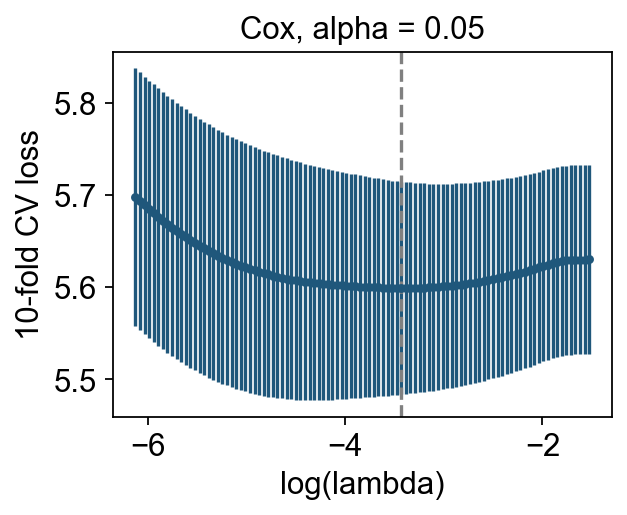

In [26]:
cv = res_os.cv_results[0]
fig, ax = plt.subplots(figsize=(4, 3))
ax.errorbar(np.log(cv.path.lambdas), cv.mean_loss, yerr=cv.standard_error, fmt='o', ms=3)
ax.axvline(np.log(cv.lambda_min), ls='--', c='grey')
ax.set(xlabel='log(lambda)', ylabel='10-fold CV loss', title=f'Cox, alpha = {cv.path.alpha}')

Inspect the CV curve and standard errors. Selection depends on lambda, alpha, the graph, the expression inputs and CV folds. Equal integer seeds in R and NumPy do **not** produce the same folds: use an exported, sample-aligned `foldid` for a cross-language equality test.


## Notes and limitations

* **Reproducibility.** The min.cells=400 filter matches the reference convention, but this example retains native OmicVerse HVGs/graph and NumPy folds. Do not attribute all count differences to the graph. A numerical equality test must share expression, graph, sample/cell order, folds, lambda path and solver semantics. Cox corrected mode is not the unchanged R implementation.
* **Alpha and cutoff.** Pass a list, e.g. `alpha=[0.005, 0.01, 0.05, 0.1, 0.2]` with `cutoff=0.03`, to let Scissor pick the first alpha that selects < 3 % of cells. Each alpha costs one full cross-validation (about 2 min here).
* **Semantics.** Use `'official'` to reproduce the R package where it is well defined (binomial); `'corrected'` is required for Cox and Gaussian on a connected graph.
* **Interpretation.** Selected cells are associated with the bulk phenotype through similarity; this is neither causal nor patient-level evidence. The original package additionally offers a permutation reliability test (`reliability.test`), which is not part of `ov.single.Scissor`.
* **Gaussian.** For a continuous phenotype pass a numeric `pd.Series` indexed by bulk sample with `family='gaussian'`; Scissor+ cells then point to higher values. `engine='numba'` accelerates the corrected Gaussian solver.